In [1]:
import pandas as pd
import json
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.family"] = "Arial"

from scipy.stats import pearsonr, ttest_ind, chi2_contingency

from additives_microbiota.plotting import process_string, process_string_pretty_vars

## Loading metadata with mixtures

In [2]:
meta = pd.read_csv("../../data/metadata_files/meta_mixtures.csv", index_col=0)

mixtures = [
    i for i in meta if "Mixture" in i and "minus" not in i and "zscore" not in i
]

# Plotting
1. Mixture-Nutrient Correlations
2. High Mixture Consumer Co-occurrence
3. Dominant Mixture distribution
4. Mixture to food group association

## Mixture-Nutrient Correlations

In [3]:
correlation_method = "pearson"


def get_filtered_correlations(df, column, threshold=0.15, method=correlation_method):
    """Get correlations, filter out patterns, and keep strong correlations."""
    corr = df.corr(numeric_only=True, method=method)[column].sort_values()
    # Filter out patterns and keep strong correlations
    mask = ~(corr.index.str.contains("minus")) & ~(corr.index.str.contains("zscore"))
    res = corr[mask & (corr.abs() > threshold)]
    return res


# Get correlations for each mixture
corr_dict = {m: get_filtered_correlations(meta, m) for m in mixtures}
var_list = list(set().union(*[set(corr.index) for corr in corr_dict.values()]))
ignore_cols = [
    "others_fg_eaten",
    "total_additive_intake",
    "energy_kj_eaten",
    "sugary_fg_eaten",
]
var_list = [i for i in var_list if i not in ignore_cols]

corr = meta[var_list].corr(numeric_only=True, method=correlation_method)

In [4]:
corr_plot_data = corr[mixtures]
corr_plot_data = corr_plot_data.drop(mixtures, axis=0)

mask_threshold = 0.05  # 0.1

# Make values with absolute value < 0.1 into NaN
corr_plot_data = corr_plot_data.mask(corr_plot_data.abs() < mask_threshold, np.nan)
corr_plot_data = corr_plot_data.sort_values(mixtures)
corr_plot_data.index = corr_plot_data.index.map(
    lambda x: process_string_pretty_vars(x, newLineSep=6)
)

In [5]:
corr_plot_data

,Mixture1,Mixture2,Mixture3
CV (Sugary),-0.245643,-0.159193,-0.051595
HEI,-0.218079,-0.121582,0.054410
Daily HEI,-0.216725,-0.137186,NaN
Beta Carotene,-0.058112,-0.070206,0.254692
Iron,-0.051653,NaN,0.503867
CV (Vegetables),0.090689,0.162252,NaN
Sweets Salty Snacks Alcohol,0.128982,0.431182,NaN
Fat,0.169270,NaN,NaN
Fatty Acids Saturated,0.197500,NaN,NaN
Salt,0.233459,0.076304,NaN


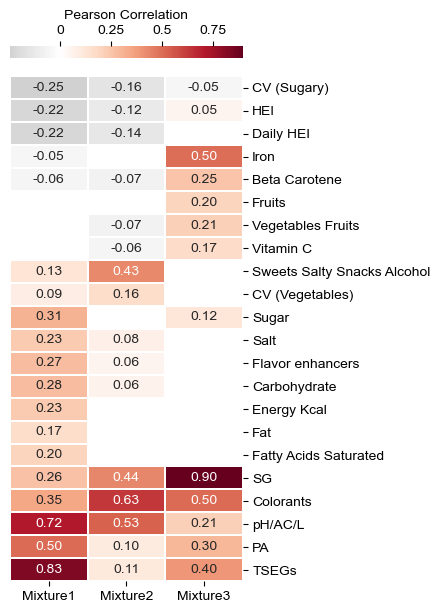

In [6]:
# First cluster to get the ordering
g = sns.clustermap(
    corr_plot_data.fillna(0),
    cmap="RdGy_r",
    center=0,
    annot=False,
    figsize=(4, 8),
    col_cluster=False,
)
plt.close()

# Get the row and column indices from the clustered data
row_order = g.dendrogram_row.reordered_ind

# Create a new heatmap with the same ordering but without dendrograms
plt.figure(figsize=(3, 8))
ax = sns.heatmap(
    corr_plot_data.iloc[row_order,],
    cmap="RdGy_r",
    center=0,
    fmt=".2f",
    annot=True,
    cbar_kws={
        "label": "Pearson Correlation",
        "orientation": "horizontal",
        "location": "top",
        "pad": 0.03,
    },
    linewidth=0.1,
)

# Format colorbar ticks to remove unnecessary decimals
cbar = ax.collections[0].colorbar
cbar.ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:g}"))

# Move y-axis labels to the right and make them horizontal
plt.gca().yaxis.set_label_position("right")
plt.gca().yaxis.tick_right()
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.savefig(
    "../figures/mixtures/mixtures_foodvars_correlations.png",
    dpi=300,
    bbox_inches="tight",
)

In [7]:
def get_correlation_stats(df, var="Mixture1", threshold=0.15, ignore_cols=[]):
    """
    Calculate Pearson correlation coefficients and p-values between a variable
    and all other numeric variables in the dataframe using scipy.
    """

    # Get numeric columns
    numeric_cols = df.select_dtypes(include=np.number).columns

    # Calculate correlations and p-values
    results = []
    for col in numeric_cols:
        if col != var and col not in ignore_cols:
            # Drop NaN values
            valid_data = df[[var, col]].dropna()
            if len(valid_data) > 1:  # Need at least 2 points for correlation
                corr, p_value = pearsonr(valid_data[var], valid_data[col])
                if abs(corr) >= threshold:  # Only include correlations above threshold
                    results.append(
                        {"variable": col, "correlation": corr, "p_value": p_value}
                    )

    # Convert to DataFrame and sort by correlation
    result_df = pd.DataFrame(results).sort_values("correlation")

    return result_df

In [8]:
correlation_stats = get_correlation_stats(
    meta, var="total_additive_intake", ignore_cols=ignore_cols
)
correlation_stats

,variable,correlation,p_value
8,CV_sugary_fg_eaten,-0.214009,1.455876e-11
10,shannon_entropy,-0.165541,2.011387e-07
1,daily_HEI,-0.164282,2.493330e-07
0,HEI,-0.160661,4.582766e-07
11,pielou_evenness,-0.158527,6.519487e-07
9,faith_pd,-0.154164,1.321199e-06
2,eaten_quantity_in_gram,0.184700,6.250411e-09
5,salt_eaten,0.189684,2.378801e-09
3,carb_eaten,0.191775,1.574022e-09
4,iron_eaten,0.219748,3.982435e-12


## Additional Analysis

/var/folders/kl/wv2_2q3n4z3d2bxtztx97rgc0000gn/T/ipykernel_28948/152915375.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(["No", "Yes"])
/var/folders/kl/wv2_2q3n4z3d2bxtztx97rgc0000gn/T/ipykernel_28948/152915375.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(["No", "Yes"])
/var/folders/kl/wv2_2q3n4z3d2bxtztx97rgc0000gn/T/ipykernel_28948/152915375.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(["No", "Yes"])
/var/folders/kl/wv2_2q3n4z3d2bxtztx97rgc0000gn/T/ipykernel_28948/152915375.py:66: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(["No", "Yes

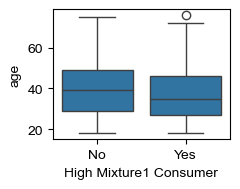

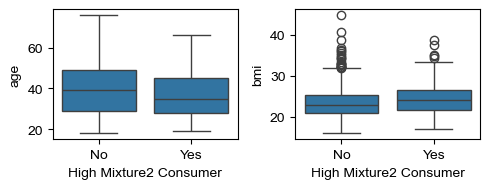

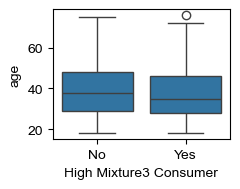

In [9]:
mixture_intake_df = meta.copy()

# Define thresholds (e.g., 75th percentile or specific value based on distribution)
thresholds = {mix: np.percentile(mixture_intake_df[mix], 75) for mix in mixtures}

# Create high consumer groups
for mix in mixtures:
    meta[f"high_{mix}"] = (mixture_intake_df[mix] > thresholds[mix]).astype(int)

# Compare demographics between high consumers and others
demographic_vars = ["age", "gender", "bmi"]

# Create summary statistics
high_consumer_stats = {}
for mix in mixtures:
    high_group = meta[meta[f"high_{mix}"] == 1]
    low_group = meta[meta[f"high_{mix}"] == 0]

    stats = {}
    for var in demographic_vars:
        if meta[var].dtype in ["int64", "float64"]:
            # For numeric variables
            stats[var] = {
                "high_mean": high_group[var].mean(),
                "high_std": high_group[var].std(),
                "low_mean": low_group[var].mean(),
                "low_std": low_group[var].std(),
                "p_value": ttest_ind(
                    high_group[var].dropna(), low_group[var].dropna()
                ).pvalue,
            }
        else:
            # For categorical variables
            contingency = pd.crosstab(meta[var], meta[f"high_{mix}"])
            stats[var] = {
                "counts": contingency,
                "p_value": chi2_contingency(contingency)[1],
            }

    high_consumer_stats[mix] = stats

# Visualize significant differences
significant_vars = {}
for mix in mixtures:
    significant_vars[mix] = [
        var
        for var in demographic_vars
        if "p_value" in high_consumer_stats[mix][var]
        and high_consumer_stats[mix][var]["p_value"] < 0.05
    ]

# Plot these significant differences
for mix in mixtures:
    if significant_vars[mix]:
        fig, axes = plt.subplots(
            1, len(significant_vars[mix]), figsize=(2.5 * len(significant_vars[mix]), 2)
        )
        if len(significant_vars[mix]) == 1:
            axes = [axes]

        for i, var in enumerate(significant_vars[mix]):
            if meta[var].dtype in ["int64", "float64"]:
                # For numeric variables, use boxplots
                sns.boxplot(x=f"high_{mix}", y=var, data=meta, ax=axes[i])
                axes[i].set_xlabel(f"High {mix} Consumer")
                axes[i].set_xticklabels(["No", "Yes"])
            else:
                # For categorical variables, use stacked bars
                pd.crosstab(meta[var], meta[f"high_{mix}"], normalize="columns").plot(
                    kind="bar", stacked=True, ax=axes[i]
                )
                axes[i].set_xlabel(var)

        plt.tight_layout()
        # plt.savefig(
        #     f"../figures/high_{mix}_demographics.png", dpi=300, bbox_inches="tight"
        # )

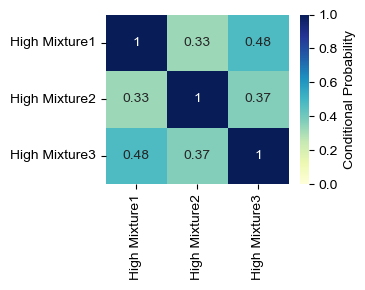

In [10]:
# Define thresholds (e.g., 75th percentile or specific value based on distribution)
thresholds = {mix: np.percentile(mixture_intake_df[mix], 75) for mix in mixtures}

# Create high consumer groups
for mix in mixtures:
    meta[f"high_{mix}"] = (mixture_intake_df[mix] > thresholds[mix]).astype(int)

# Create a co-occurrence matrix
high_mix_cols = [f"high_{mix}" for mix in mixtures]
co_occurrence = meta[high_mix_cols].T @ meta[high_mix_cols]

# Normalize by diagonal to get conditional probabilities
diag = np.diag(co_occurrence)
norm_co_occurrence = co_occurrence / diag[:, None]

# Process axis labels to make them more readable
processed_labels = [process_string(mix) for mix in high_mix_cols]

plt.figure(figsize=(3.7, 3))
heatmap = sns.heatmap(norm_co_occurrence, annot=True, cmap="YlGnBu", vmin=0, vmax=1)
plt.yticks(rotation=0)
plt.xticks(ticks=np.arange(len(processed_labels)) + 0.5, labels=processed_labels)
plt.yticks(ticks=np.arange(len(processed_labels)) + 0.5, labels=processed_labels)
# plt.title("Conditional Probability of High Mixture Scores")
cbar = heatmap.collections[0].colorbar
cbar.set_label("Conditional Probability")
plt.tight_layout()
plt.savefig(
    "../figures/mixtures/mixture_co_occurrence.png", dpi=300, bbox_inches="tight"
)

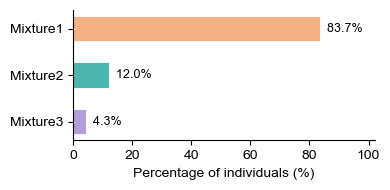

In [24]:
# For each individual, identify which mixture has the highest score
mixture_intake_df = meta.copy()

mixture_intake_df["dominant_mixture"] = mixture_intake_df[mixtures].idxmax(axis=1)

# Calculate the percentage of individuals dominated by each mixture
dominance_counts = (
    mixture_intake_df["dominant_mixture"].value_counts(normalize=True) * 100
)

# map custom colors to bars in correct order
# mixture_colors = {"Mixture1": "#c49a6c", "Mixture2": "#2f6f73", "Mixture3": "#9b7bbd"}
mixture_colors = {"Mixture1": "#f4b183", "Mixture2": "#4db6ac", "Mixture3": "#b39ddb"}
bar_colors = [mixture_colors[mix] for mix in dominance_counts.index]

fig, ax = plt.subplots(figsize=(4, 2))
y = np.arange(len(dominance_counts))
ax.barh(
    y,
    dominance_counts.values,
    height=0.55,
    color=bar_colors,
    edgecolor="white",
    linewidth=0.6,
)
ax.set_yticks(y)
ax.set_yticklabels(dominance_counts.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("Percentage of individuals (%)", fontsize=10)

for yi, val in zip(y, dominance_counts.values):
    ax.text(
        val,
        yi,
        f"  {val:.1f}%",
        va="center",
        ha="left",
        fontsize=9,
    )

xmax = float(dominance_counts.max())
if xmax > 0:
    ax.set_xlim(0, xmax * 1.22)

sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(
    "../figures/mixtures/mixture_dominance_bar.png", dpi=300, bbox_inches="tight"
)

##  Mixture to food group association

In [12]:
food_group_consumption_by_user = pd.read_csv(
    "../../data/additive_analysis_files/food_group_consumption_by_user.csv", index_col=0
)

food_group_consumption_by_user.rename(
    columns=lambda x: x.replace("fc_", ""), inplace=True
)

food_group_consumption_by_user.head()

In [13]:
merged_food_group_meta = meta.merge(
    food_group_consumption_by_user, left_on="subject_key", right_on="subject_key"
)

mixture_fg_corr_df = merged_food_group_meta[
    mixtures + list(food_group_consumption_by_user.columns)
].corr(method="spearman")[["Mixture1", "Mixture2", "Mixture3"]]

mixture_fg_corr_df = mixture_fg_corr_df.drop(mixtures, axis=0)
mixture_fg_corr_df

,Mixture1,Mixture2,Mixture3
alcoholic_beverages,0.048406,0.203060,-0.019629
breakfast_cereals,0.173834,-0.025590,0.123409
carbonated_soft_drinks,0.243530,0.649610,0.052748
cheese,0.146030,0.130527,-0.006375
chocolates_candies_sweets,0.555752,0.009862,0.377376
energy_drinks,0.151992,0.235446,0.004832
frozen_desserts_and_ice_cream,0.261182,0.001569,0.041831
fruits_and_vegetables,0.171859,0.099868,-0.010927
juices_syrups,0.173686,0.172139,-0.016086
meat_and_seafood,0.204455,0.106589,0.010881


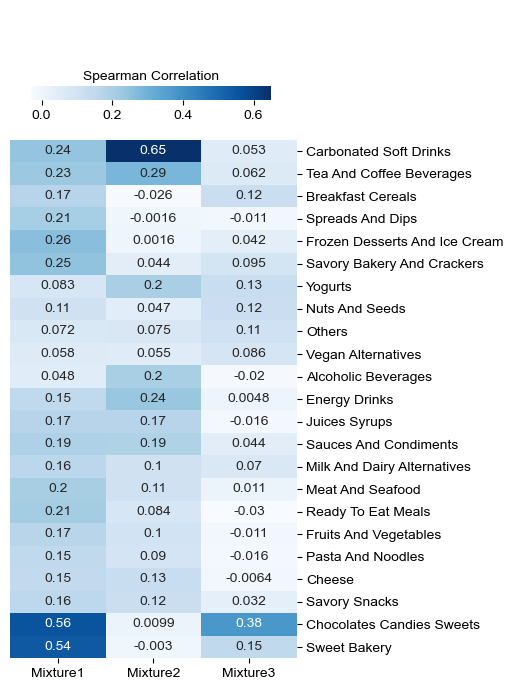

In [14]:
g = sns.clustermap(
    mixture_fg_corr_df,
    col_cluster=False,
    annot=True,
    cmap="Blues",
    # center=0,
    figsize=(6, 7),
    cbar_kws={
        "label": "Spearman Correlation",
        "orientation": "horizontal",
        "shrink": 0.5,
    },
)

# Hide row dendrogram but keep clustering
g.ax_row_dendrogram.set_visible(False)

# Move the colorbar to the custom position
g.cax.set_position((0.18, 0.85, 0.4, 0.02))  # (left, bottom, width, height)
g.cax.xaxis.set_label_position("top")

# Apply process_string function to y-ticklabels
new_labels = [process_string(lbl.get_text()) for lbl in g.ax_heatmap.get_yticklabels()]
g.ax_heatmap.set_yticklabels(new_labels)
print("")

plt.savefig(
    "../figures/mixtures/mixture_foodgroup_correlations.png",
    dpi=300,
    bbox_inches="tight",
)

In [15]:
diversity_vars = ["shannon_entropy", "pielou_evenness", "faith_pd", "observed_features"]

fg_corr_df = merged_food_group_meta[
    diversity_vars + list(food_group_consumption_by_user.columns)
].corr()[diversity_vars]

fg_corr_df = fg_corr_df.drop(diversity_vars, axis=0)

print(
    "Found",
    fg_corr_df[fg_corr_df["shannon_entropy"].abs() > 0.1].shape[0],
    "food groups with |shannon entropy| correlation > 0.1",
)

fg_corr_df  # "shannon_entropy"].sort_values()

Found 0 food groups with |shannon entropy| correlation > 0.1


,shannon_entropy,pielou_evenness,faith_pd,observed_features
alcoholic_beverages,-0.016486,0.017255,-0.080739,-0.048843
breakfast_cereals,-0.018334,-0.024217,-0.028534,-0.008338
carbonated_soft_drinks,-0.072443,-0.084570,-0.058023,-0.044362
cheese,-0.042261,-0.044864,-0.006685,-0.017872
chocolates_candies_sweets,-0.049677,-0.054645,-0.057141,-0.026184
energy_drinks,-0.033719,-0.042087,0.001232,-0.021109
frozen_desserts_and_ice_cream,-0.076512,-0.057054,-0.092644,-0.084981
fruits_and_vegetables,0.044602,0.034195,0.025621,0.035551
juices_syrups,-0.087163,-0.092529,-0.072675,-0.059949
meat_and_seafood,-0.056973,-0.084366,-0.025495,-0.021360


In [16]:
merged_food_group_meta[diversity_vars + mixtures].corr()[diversity_vars]

,shannon_entropy,pielou_evenness,faith_pd,observed_features
shannon_entropy,1.000000,0.885659,0.774797,0.866898
pielou_evenness,0.885659,1.000000,0.475287,0.547493
faith_pd,0.774797,0.475287,1.000000,0.908581
observed_features,0.866898,0.547493,0.908581,1.000000
Mixture1,-0.110377,-0.113118,-0.108258,-0.084079
Mixture2,-0.054175,-0.077273,-0.035429,-0.022995
Mixture3,-0.103403,-0.085053,-0.101474,-0.085454
